<a href="https://colab.research.google.com/github/LexDomingues/Fine-tuning_YOLO/blob/main/Fine_tuning_the_YOLO_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 1.9 MB/s eta 0:00:00


In [2]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
model = YOLO("yolo11n.pt")

In [4]:
resultados = model.train(
    data="coco128.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    patience=3,
    project="/content/yolo_coco",
    name="transfer_learning"
)

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=transfer_learning, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

In [5]:
metricas = model.val(data="coco128.yaml")

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 922.3±266.9 MB/s, size: 44.1 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 29.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.5s/it 20.1s
                   all        128        929      0.785      0.659      0.728      0.553
                person         61        254      0.884      0.602      0.806      0.551
               bicycle          3          6      0.559      0.167      0.417      0.266
                   car         12         46      0.811      0.217      0.344      0.201
            motorcycle          4          5       0.91          1      0.995      0.875
              airplane          5


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 skateboard, 141.5ms
Speed: 4.9ms preprocess, 141.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict


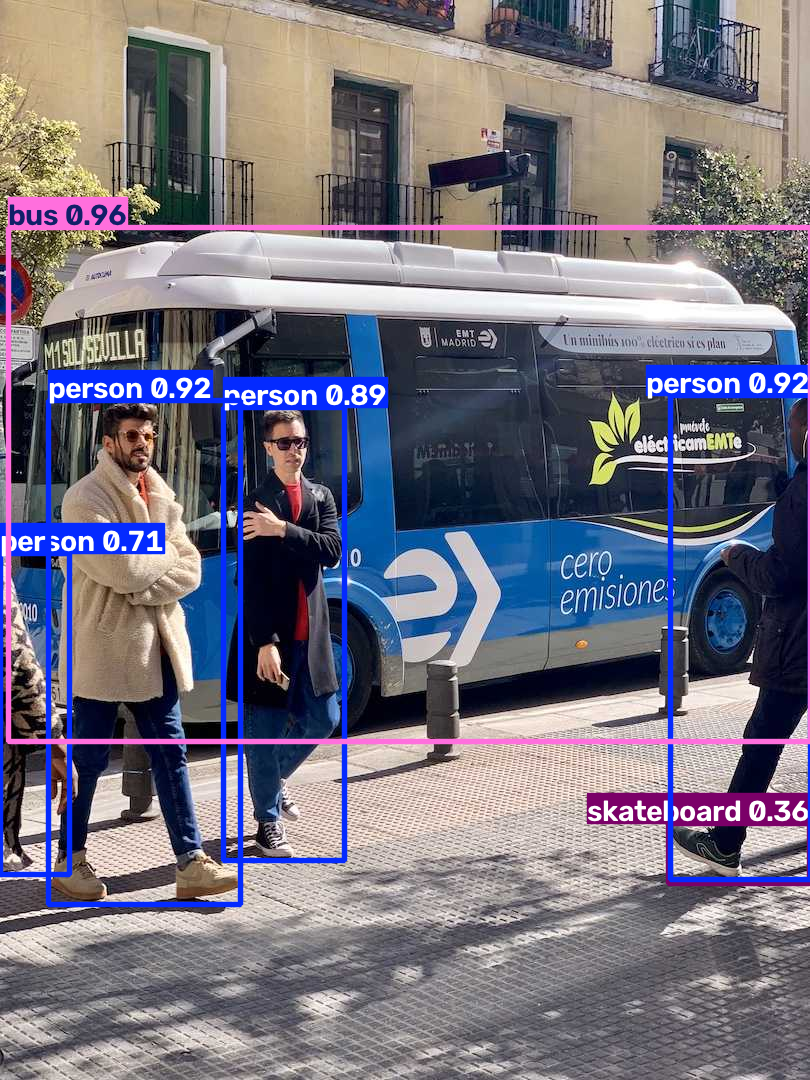

In [6]:
resultados_teste = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    save=True
)

imagem = resultados_teste[0].plot()
display(Image.fromarray(imagem[:, :, ::-1]))

In [9]:
model.save("/content/drive/MyDrive/Modelo_fine_tuning.YOLO")